**STEP 1**

In [4]:


import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Load cleaned dataset
df = pd.read_csv(
    '/content/sample_data/applicants_cleaned.csv',
    parse_dates=['Application Date']
)

# Set a consistent visualization style
sns.set_theme(style="whitegrid")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

# Check dataset information
df.info()

# Display first five rows
display(df.head())

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())


Dataset loaded successfully!
Dataset shape: (78, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 78 entries, 0 to 77
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Applicant Name    78 non-null     object        
 1   Email             77 non-null     object        
 2   Phone             78 non-null     int64         
 3   Domain Applied    1 non-null      object        
 4   University        78 non-null     object        
 5   Application Date  76 non-null     datetime64[ns]
 6   Status            78 non-null     object        
dtypes: datetime64[ns](1), int64(1), object(5)
memory usage: 4.4+ KB


,Applicant Name,Email,Phone,Domain Applied,University,Application Date,Status
0,Muneeb Sheikh,muneeb.sheikh4@yahoo.com,3242868828,NaN,COMSATS University Islamabad,2026-02-22,Rejected
1,Eman Malik,eman.malik76@outlook.com,3013999315,NaN,National University of Sciences and Technology,2026-04-30,Rejected
2,Anum Khan,anum.khan72@gmail.com,3466306997,NaN,Bahria University,2026-05-23,Under Review
3,Ali Khan,abdullah.iqbal90@outlook.com,3247295260,NaN,National University of Sciences and Technology,2026-06-22,Under Review
4,Muhammad Javed,muhammad.javed13@outlook.com,3291030736,NaN,University of Punjab,2026-08-24,Rejected



Missing values:
Applicant Name       0
Email                1
Phone                0
Domain Applied      77
University           0
Application Date     2
Status               0
dtype: int64

Duplicate rows: 0


**STEP :2**

Applications per Domain:


,Number of Applications
Domain Applied,
Web Development,1


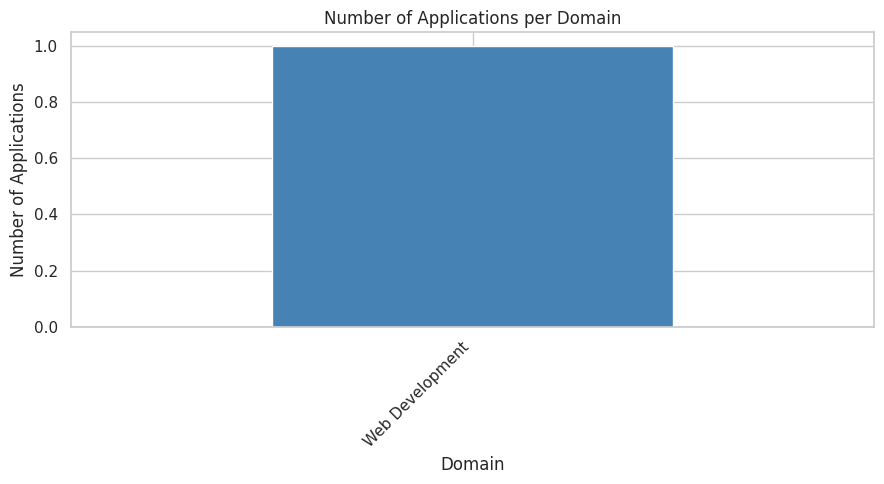

Takeaway: Web Development received the most applications (1), while Web Development received the fewest (1).


In [5]:

# Count applications for each domain
domain_counts = df['Domain Applied'].value_counts()

print("Applications per Domain:")
display(domain_counts.to_frame(name='Number of Applications'))

# Create bar chart
plt.figure(figsize=(9, 5))

domain_counts.plot(kind='bar', color='steelblue')

plt.title('Number of Applications per Domain')
plt.xlabel('Domain')
plt.ylabel('Number of Applications')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Automatically generate takeaway
highest_domain = domain_counts.idxmax()
highest_count = domain_counts.max()

lowest_domain = domain_counts.idxmin()
lowest_count = domain_counts.min()

print(
    f"Takeaway: {highest_domain} received the most applications "
    f"({highest_count}), while {lowest_domain} received the fewest "
    f"({lowest_count})."
)


**STEP 3**

Monthly Application Trend:


,Applications
Application Month,
2026-01,6
2026-02,7
2026-03,6
2026-04,12
2026-05,10
2026-06,9
2026-07,7
2026-08,9
2026-09,8


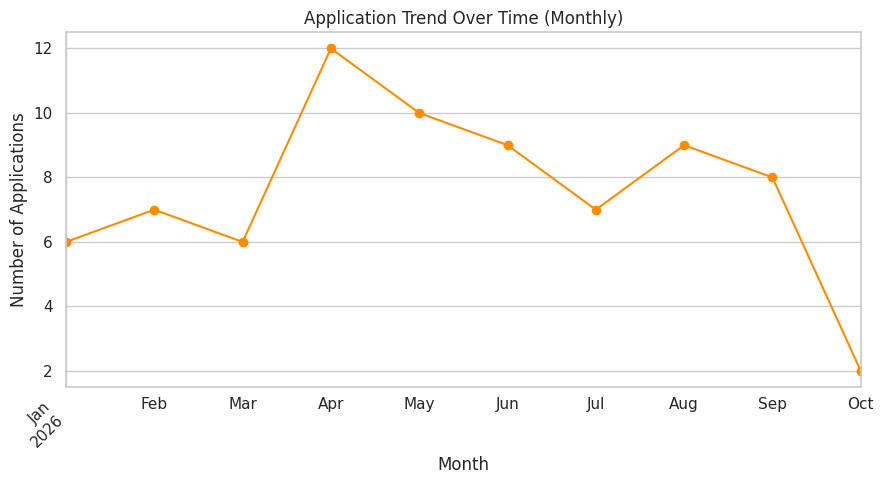

Takeaway: The highest number of applications (12) was recorded in 2026-04.


In [6]:

# Group applications by month
df['Application Month'] = (
    df['Application Date'].dt.to_period('M')
)

monthly_trend = df.groupby('Application Month').size()

print("Monthly Application Trend:")
display(monthly_trend.to_frame(name='Applications'))

# Create line chart
plt.figure(figsize=(9, 5))

monthly_trend.plot(
    kind='line',
    marker='o',
    color='darkorange'
)

plt.title('Application Trend Over Time (Monthly)')
plt.xlabel('Month')
plt.ylabel('Number of Applications')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Automatically identify the month with the most applications
if not monthly_trend.empty:
    peak_month = str(monthly_trend.idxmax())
    peak_count = monthly_trend.max()

    print(
        f"Takeaway: The highest number of applications "
        f"({peak_count}) was recorded in {peak_month}."
    )


**STEP 4**

Overall Application Status:


,Count
Status,
Under Review,29
Selected,25
Rejected,24


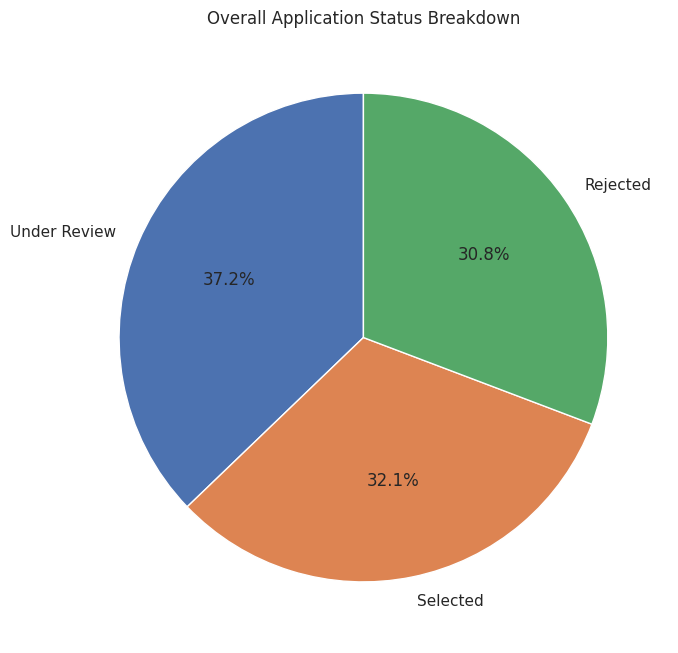

Application Status by Domain:


Status,Under Review
Domain Applied,
Web Development,1


Status Percentages by Domain:


Status,Under Review
Domain Applied,
Web Development,100.0


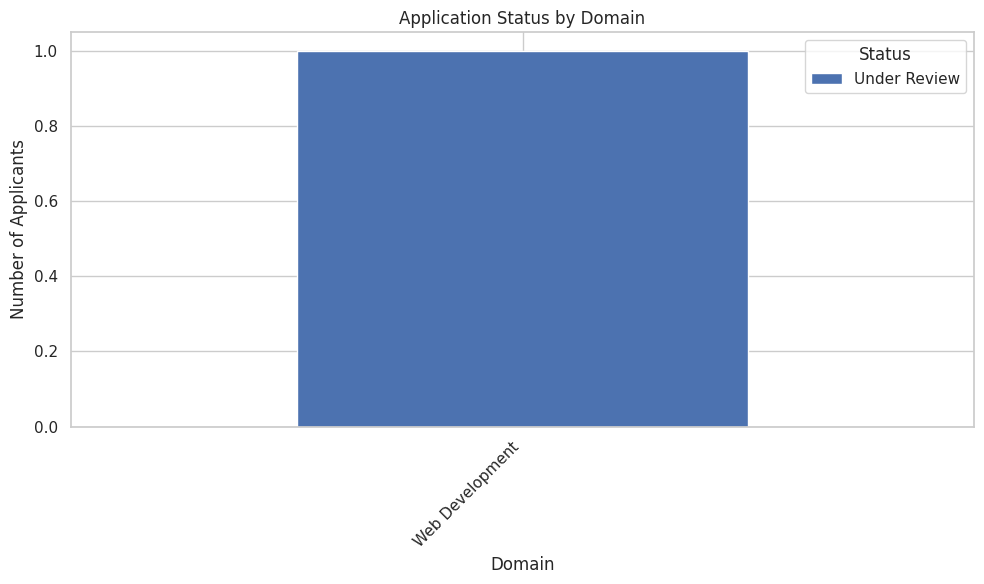

No 'Selected' status was found. Check the actual status labels in the dataset before calculating acceptance rates.


In [7]:

# Count each application status
status_counts = df['Status'].value_counts()

print("Overall Application Status:")
display(status_counts.to_frame(name='Count'))

# Pie chart for overall status
plt.figure(figsize=(7, 7))

status_counts.plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Overall Application Status Breakdown')
plt.ylabel('')
plt.tight_layout()
plt.show()

# Create a pivot table: Domain vs Status
status_by_domain = pd.pivot_table(
    df,
    index='Domain Applied',
    columns='Status',
    values='Applicant Name',
    aggfunc='count',
    fill_value=0
)

print("Application Status by Domain:")
display(status_by_domain)

# Calculate percentages for each domain
status_by_domain_pct = (
    status_by_domain
    .div(status_by_domain.sum(axis=1).replace(0, 1), axis=0)
    * 100
)

print("Status Percentages by Domain:")
display(status_by_domain_pct.round(1))

# Grouped bar chart
status_by_domain.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Application Status by Domain')
plt.xlabel('Domain')
plt.ylabel('Number of Applicants')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Status')
plt.tight_layout()
plt.show()

# Calculate Selected percentage for every domain
# This assumes that the selection status is named "Selected".
selected_columns = [
    col for col in status_by_domain.columns
    if str(col).strip().casefold() == 'selected'
]

if selected_columns:
    selected_col = selected_columns[0]

    acceptance_rate = (
        status_by_domain[selected_col]
        / status_by_domain.sum(axis=1).replace(0, 1)
        * 100
    )

    print("Selection Rate by Domain (%):")
    display(acceptance_rate.round(1).to_frame(
        name='Selection Rate (%)'
    ))

    highest_rate_domain = acceptance_rate.idxmax()

    print(
        f"Takeaway: {highest_rate_domain} has the highest "
        f"selection rate ({acceptance_rate.max():.1f}%)."
    )
else:
    print(
        "No 'Selected' status was found. Check the actual status "
        "labels in the dataset before calculating acceptance rates."
    )


STEP 5:

Top 10 Universities:


,Number of Applicants
University,
FAST-NUCES,12
Bahria University,10
National University of Sciences and Technology,9
COMSATS University Islamabad,8
UET Lahore,8
University of Punjab,7
University of Sargodha,6
Virtual University of Pakistan,6
Air University,5


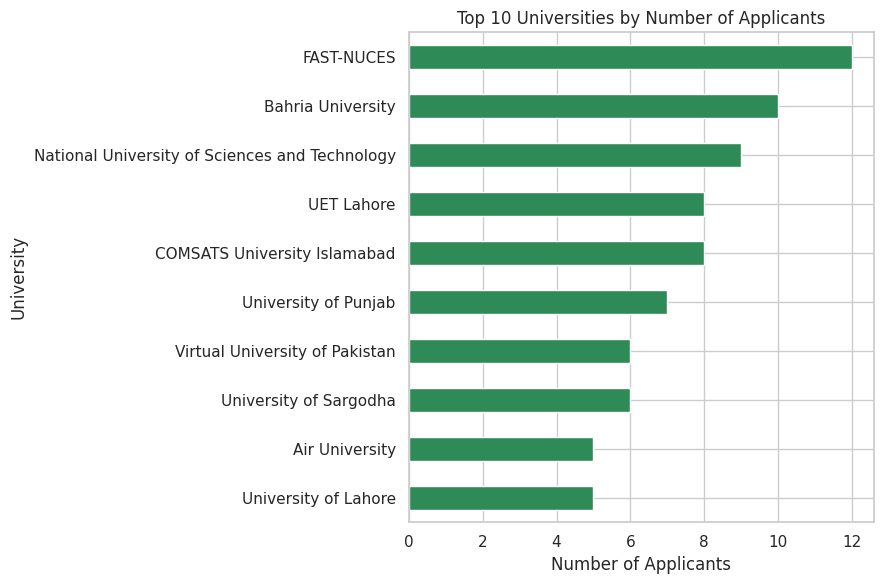

Takeaway: FAST-NUCES contributed the most applicants (12).


In [8]:

# Count applications by university
top_universities = (
    df['University']
    .value_counts()
    .head(10)
)

print("Top 10 Universities:")
display(top_universities.to_frame(
    name='Number of Applicants'
))

# Create horizontal bar chart
plt.figure(figsize=(9, 6))

top_universities.sort_values().plot(
    kind='barh',
    color='seagreen'
)

plt.title('Top 10 Universities by Number of Applicants')
plt.xlabel('Number of Applicants')
plt.ylabel('University')
plt.tight_layout()
plt.show()

# Generate takeaway
if not top_universities.empty:
    print(
        f"Takeaway: {top_universities.idxmax()} contributed "
        f"the most applicants ({top_universities.max()})."
    )


**STEP 6**

Applications by Day of Week:


,Applications
Day of Week,
Monday,9
Tuesday,16
Wednesday,8
Thursday,13
Friday,12
Saturday,8
Sunday,10


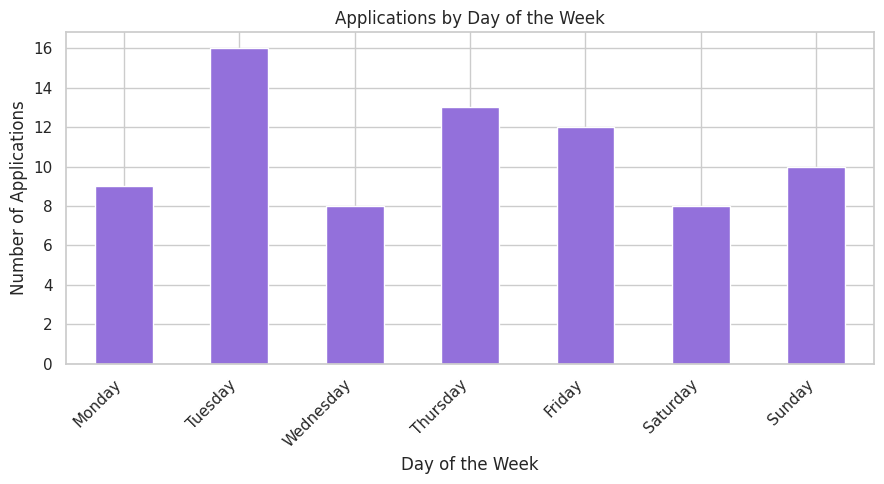

Takeaway: Tuesday had the highest number of applications (16).


In [9]:

# Extract day of the week from application date
df['Day of Week'] = df['Application Date'].dt.day_name()

# Arrange days in calendar order
day_order = [
    'Monday', 'Tuesday', 'Wednesday', 'Thursday',
    'Friday', 'Saturday', 'Sunday'
]

weekday_counts = (
    df['Day of Week']
    .value_counts()
    .reindex(day_order, fill_value=0)
)

print("Applications by Day of Week:")
display(weekday_counts.to_frame(name='Applications'))

# Create bonus chart
plt.figure(figsize=(9, 5))

weekday_counts.plot(
    kind='bar',
    color='mediumpurple'
)

plt.title('Applications by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Number of Applications')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Generate takeaway
if not weekday_counts.empty:
    busiest_day = weekday_counts.idxmax()
    busiest_count = weekday_counts.max()

    print(
        f"Takeaway: {busiest_day} had the highest number "
        f"of applications ({busiest_count})."
    )


STEP 7

In [10]:

###=======================================================
KEY INSIGHTS
=======================================================
1. ##Web Development was the most popular domain, with 1 applications.
2. ##2026-04 had the highest monthly application volume, with 12 applications.
3. ##The most common application status was 'Under Review', accounting for 29 applications.
5. ##FAST-NUCES contributed the most applicants among universities, with 12 applications.



KEY INSIGHTS
1. Web Development was the most popular domain, with 1 applications.
2. 2026-04 had the highest monthly application volume, with 12 applications.
3. The most common application status was 'Under Review', accounting for 29 applications.
5. FAST-NUCES contributed the most applicants among universities, with 12 applications.


**STEP 8 **

In [11]:

# Save the monthly trend
monthly_trend.to_csv('monthly_application_trend.csv')

# Save domain counts
domain_counts.to_csv('domain_application_counts.csv')

# Save status-by-domain table
status_by_domain.to_csv('application_status_by_domain.csv')

# Save selection rates if available
if selected_columns:
    acceptance_rate.round(2).to_csv('selection_rates_by_domain.csv')

print("Analysis completed successfully!")
print("All required charts and summary tables have been generated.")


Analysis completed successfully!
All required charts and summary tables have been generated.
